<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


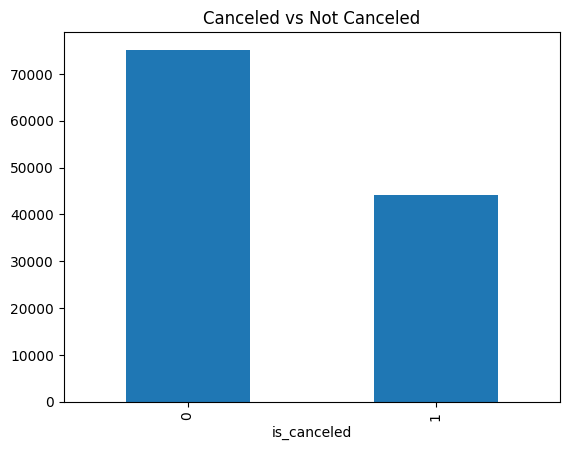

In [ ]:
df['is_canceled'].value_counts().plot(kind='bar')
plt.title('Canceled vs Not Canceled')
plt.show()

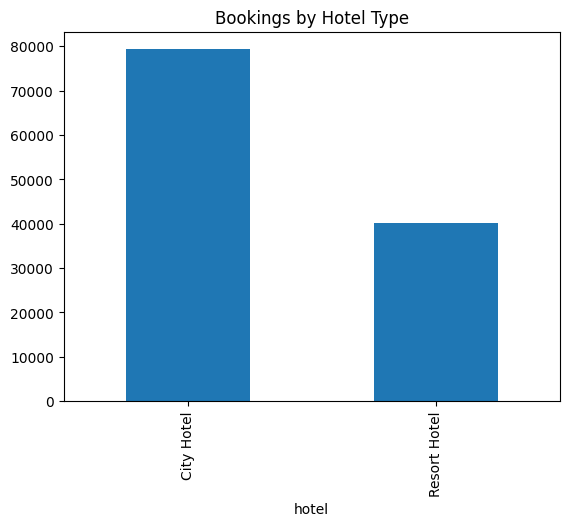

In [ ]:
df['hotel'].value_counts().plot(kind='bar')
plt.title('Bookings by Hotel Type')
plt.show()

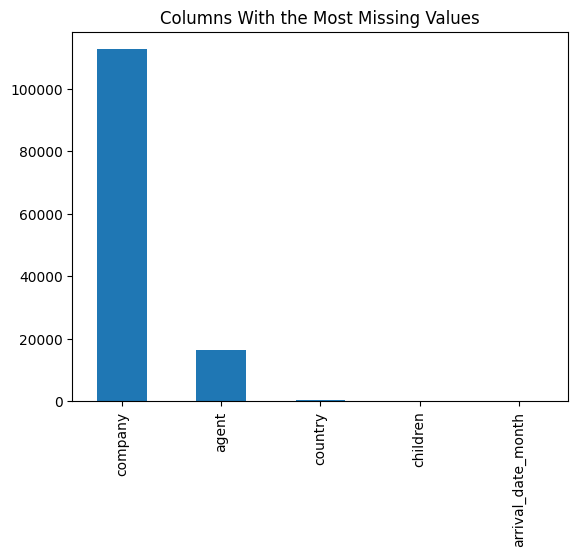

In [ ]:
df.isna().sum().sort_values(ascending=False).head(5).plot(kind='bar')
plt.title('Columns With the Most Missing Values')
plt.show()

In [ ]:
df.groupby('deposit_type')['is_canceled'].mean()

,is_canceled
deposit_type,
No Deposit,0.283770
Non Refund,0.993624
Refundable,0.222222


In [ ]:
df['deposit_type'].value_counts()

,count
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


In [ ]:
df[df['deposit_type'] == 'Non Refund']['distribution_channel'].value_counts()

,count
distribution_channel,
TA/TO,13651
Corporate,538
Direct,398


rows: 104803 | base cancellation rate: 28.4%

                 n  lead_min  lead_max  cancel_rate
lead_decile                                        
0            11842         0         2          7.9
1             9889         3         9         12.9
2             9779        10        20         24.3
3            10513        21        36         30.1
4            10813        37        57         33.4
5            10123        58        83         32.4
6            10421        84       117         34.2
7            10557       118       162         34.5
8            10435       163       223         35.4
9            10431       224       737         40.0


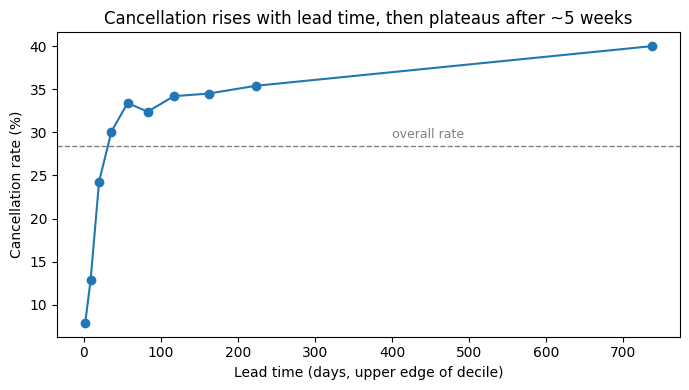

In [ ]:
#Checking the intuition that longer lead times mean more cancellations
# Non Refund bookings are excluded: 81 of 87 agents cancel at exactly 100% on them,
# while the same agents cancel at 15-39% on their No Deposit bookings. Treating those
import numpy as np
clean = df[df['deposit_type'] != 'Non Refund'].copy()
print('rows:', len(clean), '| base cancellation rate: %.1f%%' % (clean['is_canceled'].mean()*100))

clean['lead_decile'] = pd.qcut(clean['lead_time'], 10, labels=False, duplicates='drop')
trend = clean.groupby('lead_decile').agg(
    n=('is_canceled', 'size'),
    lead_min=('lead_time', 'min'),
    lead_max=('lead_time', 'max'),
    cancel_rate=('is_canceled', 'mean'))
trend['cancel_rate'] = (trend['cancel_rate']*100).round(1)
print()
print(trend)

ax = trend.plot(x='lead_max', y='cancel_rate', marker='o', legend=False, figsize=(7,4))
ax.set_xlabel('Lead time (days, upper edge of decile)')
ax.set_ylabel('Cancellation rate (%)')
ax.set_title('Cancellation rises with lead time, then plateaus after ~5 weeks')
ax.axhline(clean['is_canceled'].mean()*100, ls='--', c='grey', lw=1)
ax.text(400, clean['is_canceled'].mean()*100+1, 'overall rate', color='grey', fontsize=9)
plt.tight_layout(); plt.show()